# fedOPD · Exploratory Data Analysis
**Cross-silo federated forecasting of NHS outpatient (RTT) demand — operations research, not clinical.**

EDA on NHS England **Referral-to-Treatment** data: 96 monthly files, `2018-04 → 2026-03` (8 financial years).
Goal — verify the raw data, build the canonical **`[date, branch, dept, demand]`** table, and characterise it
enough to (a) select federated clients and (b) design the forecaster.

- **Grain:** trust × treatment function × month.
- **Demand:** `RTT Part Type == Part_3` (new RTT periods), column `Total All`.
- **Client:** one NHS trust (3-char `R##` provider code); independents (5-char) excluded.
- **Hierarchy:** NHS England → region → ICB (`Provider Parent`) → trust → department.

This **single notebook** runs stages 2 → 8 in sequence. Each stage ends with quantified findings (`F-xx`)
and decisions (`D-xx`) that are copied into `docs/WORKLOG.md`. Derived tables → `reports/tables/`,
figures → `reports/figures/`. Raw `data/` is read-only.

## Stage 2 · Input & inspect

**Questions this stage answers:**
(a) all 96 files exist and read · (b) the 9 canonical columns are present in every era ·
(c) the exact `Part_3` demand label · (d) trust vs independent provider-code split ·
(e) `C_999` aggregate specialty present · (f) `Period` parses (incl. the `APRIL`/`April` case quirk) ·
(g) `Total All` is numeric · (h) national totals match externally-verified figures ·
(i) schema is consistent across all 96 files.

**Sentinel months** (develop on 4; full 96-file passes only where marked): `2018-04` oldest / first modern
layout (69 cols) · `2020-04` COVID collapse · `2021-04` layout step to 121 cols · `2026-03` newest.

**Done when** `D-01` (loader `usecols` + parse rules) is logged.

In [1]:
import sys , platform , datetime as dt
import pandas as pd , numpy as np


print(dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "|", platform.node())

print("username : Nilesh")

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

2026-07-11 04:27:50 | ubuntu-Standard-PC-Q35-ICH9-2009
username : Nilesh
python 3.10.12 | pandas 2.3.3 | numpy 2.2.6


In [2]:
import os , shutil , subprocess , platform 

print("System Specifications")

cpu = platform.processor()
if shutil.which("lscpu"):                                            # lscpu gives the proper model name
    out = subprocess.run(["lscpu"], capture_output=True, text=True).stdout
    cpu = next((l.split(":",1)[1].strip() for l in out.splitlines()
                if l.startswith("Model name")), cpu)                 # grab the "Model name" line
print(f"CPU: {cpu} | {os.cpu_count()} cores")   

ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
print(f"RAM: {ram_gb:.0f} GB")

if shutil.which("nvidia-smi"):
    q = subprocess.run(["nvidia-smi",
 "--query-gpu=name,memory.total,memory.used",
 "--format=csv,noheader"], capture_output=True, text=True)
    print("GPU:" , q.stdout.strip())


System Specifications
CPU: Intel Xeon Processor (Cascadelake) | 42 cores
RAM: 67 GB
GPU: NVIDIA A100 80GB PCIe, 81920 MiB, 1 MiB


In [3]:
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "CLAUDE.md").exists())
DATA = ROOT / "data" / "nhs_rtt_referral_to_treatment"
files = sorted(DATA.glob("rtt_*.csv"))

print(len(files), "files:", files[0].name, "→", files[-1].name) 
sizes = [f.stat().st_size/1e6 for f in files]
print(f"MB: min {min(sizes):.0f} max {max(sizes):.0f}")
assert len(files) == 96  

96 files: rtt_2018-04.csv → rtt_2026-03.csv
MB: min 42 max 114


In [4]:
print("Sentinel Months placed as markers")
Sentinels = ["2018-04", "2020-04", "2021-04", "2026-03"]       # sentinels: oldest, COVID crash, mid, newest
df = {m: pd.read_csv(DATA/f"rtt_{m}.csv",              # read each sentinel into a dict of DataFrames
                     low_memory=False) for m in Sentinels}     # low_memory=False: infer dtypes from whole file
for m in Sentinels: print(m, df[m].shape)                      # rows × columns per era (expect 69 vs 121 cols)

Sentinel Months placed as markers


2018-04 (196340, 69)
2020-04 (125460, 69)
2021-04 (160251, 121)
2026-03 (183400, 121)


In [5]:
print("All columns present (schema grows 69 -> 121 across the window)")
new = df["2026-03"].columns                                   # newest era is the superset (121 cols)
old = set(df["2018-04"].columns)                              # oldest era (69 cols)
for i, c in enumerate(new, 1):
    print(f"{i:>3}. {c}" + ("" if c in old else "   (2021+ only)"))  # flag columns added later

All columns present (schema grows 69 -> 121 across the window)
  1. Period
  2. Provider Parent Org Code
  3. Provider Parent Name
  4. Provider Org Code
  5. Provider Org Name
  6. Commissioner Parent Org Code
  7. Commissioner Parent Name
  8. Commissioner Org Code
  9. Commissioner Org Name
 10. RTT Part Type
 11. RTT Part Description
 12. Treatment Function Code
 13. Treatment Function Name
 14. Gt 00 To 01 Weeks SUM 1
 15. Gt 01 To 02 Weeks SUM 1
 16. Gt 02 To 03 Weeks SUM 1
 17. Gt 03 To 04 Weeks SUM 1
 18. Gt 04 To 05 Weeks SUM 1
 19. Gt 05 To 06 Weeks SUM 1
 20. Gt 06 To 07 Weeks SUM 1
 21. Gt 07 To 08 Weeks SUM 1
 22. Gt 08 To 09 Weeks SUM 1
 23. Gt 09 To 10 Weeks SUM 1
 24. Gt 10 To 11 Weeks SUM 1
 25. Gt 11 To 12 Weeks SUM 1
 26. Gt 12 To 13 Weeks SUM 1
 27. Gt 13 To 14 Weeks SUM 1
 28. Gt 14 To 15 Weeks SUM 1
 29. Gt 15 To 16 Weeks SUM 1
 30. Gt 16 To 17 Weeks SUM 1
 31. Gt 17 To 18 Weeks SUM 1
 32. Gt 18 To 19 Weeks SUM 1
 33. Gt 19 To 20 Weeks SUM 1
 34. Gt 20 To 21 Weeks

In [6]:
print("Canonical Months that are most useful")
CANON = ["Period","Provider Org Code","Provider Org Name",        # the 9 columns the loader
         "Treatment Function Code","Treatment Function Name",     # will depend on
         "RTT Part Type","Total All"]

for m in Sentinels:
    print(m, "missing:", [c for c in CANON if c not in df[m].columns])  # any canonical col absent?
    print("  parent cols:", [c for c in df[m].columns if "Parent" in c]) # exact Provider Parent headers

Canonical Months that are most useful
2018-04 missing: []
  parent cols: ['Provider Parent Org Code', 'Provider Parent Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name']
2020-04 missing: []
  parent cols: ['Provider Parent Org Code', 'Provider Parent Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name']
2021-04 missing: []
  parent cols: ['Provider Parent Org Code', 'Provider Parent Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name']
2026-03 missing: []
  parent cols: ['Provider Parent Org Code', 'Provider Parent Name', 'Commissioner Parent Org Code', 'Commissioner Parent Name']


In [7]:
# C7 · part-type labels per era — the demand filter string ("Part_3") must be exact
#      and present in every era; note where "Part_2A" (decision-to-admit) first appears.
for m in Sentinels:
    print(m, sorted(df[m]["RTT Part Type"].astype(str).unique()))   # distinct pathway labels

2018-04 ['Part_1A', 'Part_1B', 'Part_2', 'Part_2A', 'Part_3']
2020-04 ['Part_1A', 'Part_1B', 'Part_2', 'Part_2A', 'Part_3']
2021-04 ['Part_1A', 'Part_1B', 'Part_2', 'Part_2A', 'Part_3']
2026-03 ['Part_1A', 'Part_1B', 'Part_2', 'Part_2A', 'Part_3']


In [8]:
# C8 · trust vs independent provider split.
#      NHS trusts = 3-char codes starting "R"; independents = 5-char codes.
#      Print the code-length histogram + the trust count vs all providers, per era.
for m in Sentinels:
    c = df[m]["Provider Org Code"].astype(str).str.strip()            # provider codes, stripped
    tr = c[(c.str.len() == 3) & c.str.upper().str.startswith("R")].nunique()  # R## trusts
    print(m, dict(c.str.len().value_counts().sort_index()),           # {code_length: count}
          "| R## trusts:", tr, "of", c.nunique(), "providers")

2018-04 {3: np.int64(167126), 5: np.int64(29214)} | R## trusts: 184 of 417 providers
2020-04 {3: np.int64(111712), 5: np.int64(13748)} | R## trusts: 173 of 414 providers


2021-04 {3: np.int64(135603), 5: np.int64(24648)} | R## trusts: 170 of 431 providers


2026-03 {3: np.int64(153044), 5: np.int64(30356)} | R## trusts: 149 of 533 providers


In [9]:
# C9 · distinct treatment functions per era, and whether the C_999 aggregate row
#      ("Total") is present (it must be, so the loader can drop it).
for m in Sentinels:
    tf = df[m][["Treatment Function Code", "Treatment Function Name"]].drop_duplicates()
    print(m, len(tf), "functions | C_999 present:",
          bool((tf["Treatment Function Code"] == "C_999").any()))

2018-04 20 functions | C_999 present: True
2020-04 20 functions | C_999 present: True
2021-04 24 functions | C_999 present: True
2026-03 24 functions | C_999 present: True


In [10]:
# C10 · Period string format + case quirk. Early files say "RTT-APRIL-2018"
#       (upper), later ones "RTT-March-2026" (title). A case-insensitive regex must
#       recover the month, and the title-cased month must equal the filename month.
import re
for m in Sentinels:
    p = str(df[m]["Period"].iloc[0])                       # Period string, first row
    g = re.search(r"([A-Za-z]+)[-_ ](\d{4})", p)           # month word + 4-digit year
    print(m, repr(p), "->", g.group(1).title(), g.group(2))  # normalised month + year

2018-04 'RTT-April-2018' -> April 2018
2020-04 'RTT-APRIL-2020' -> April 2020
2021-04 'RTT-APRIL-2021' -> April 2021
2026-03 'RTT-March-2026' -> March 2026


In [11]:
# C11 · demand column dtype + NaN count per era. If any era is `object`, the loader
#       must coerce with pd.to_numeric(errors="coerce").
for m in Sentinels:
    col = df[m]["Total All"]                               # the demand column
    print(m, col.dtype, "| NaN:", int(pd.isna(col).sum()))

2018-04 int64 | NaN: 0
2020-04 int64 | NaN: 0
2021-04 int64 | NaN: 0
2026-03 int64 | NaN: 0


In [12]:
# C12 · external validation (catches any wrong filter). Apply the full demand rule
#       — Part_3 · NHS trusts (R##) · drop C_999 — sum Total All, compare to the
#       verified national figures. Any MISMATCH => a filter is wrong; do NOT proceed.
EXPECT = {"2018-04": 1_544_011, "2020-04": 474_295,       # verified national Part_3
          "2021-04": 1_394_578, "2026-03": 1_783_457}      # totals (trusts, no C_999)

for m in Sentinels:
    d = df[m]
    c = d["Provider Org Code"].astype(str).str.strip()
    mask = ((d["RTT Part Type"] == "Part_3")                       # demand rows
            & (d["Treatment Function Code"] != "C_999")            # drop aggregate specialty
            & (c.str.len() == 3) & c.str.upper().str.startswith("R"))  # NHS trusts only
    tot = int(pd.to_numeric(d.loc[mask, "Total All"], errors="coerce").sum())
    print(m, f"{tot:,}", "vs", f"{EXPECT[m]:,}",
          "OK" if tot == EXPECT[m] else "MISMATCH")

2018-04 1,544,011 vs 1,544,011 OK
2020-04 474,295 vs 474,295 OK


2021-04 1,394,578 vs 1,394,578 OK
2026-03 1,783,457 vs 1,783,457 OK


In [13]:
# C13 · schema audit across ALL 96 files (reads only the header row of each -> fast).
#       Confirms the 7 canonical columns exist everywhere, pins the exact month the
#       column count steps 69 -> 121, and checks the parent header is one variant.
import csv
rows = []
for f in files:
    with open(f, newline="") as fh:
        head = next(csv.reader(fh))                                # header row only
    rows.append({"month": f.stem[-7:],                             # YYYY-MM
                 "ncols": len(head),                               # column count
                 "canon_ok": all(c in head for c in CANON),        # 7 canonical present?
                 "parent": next((c for c in head                   # first Provider/Commissioner
                                  if "Parent" in c and "Code" in c), None)})  # parent code header
aud = pd.DataFrame(rows)
print("all canonical present:", bool(aud.canon_ok.all()))          # must be True
print(aud.groupby("ncols").month.agg(["min", "max", "count"]))     # exact 69->121 boundary
print("parent header variants:", list(aud.parent.unique()))        # expect one name
assert aud.canon_ok.all()

all canonical present: True


           min      max  count
ncols                         
69     2018-04  2021-03     36
121    2021-04  2026-03     60
parent header variants: ['Provider Parent Org Code']


In [14]:
# C14 · content sweep across ALL 96 files (reads only the 2 columns that matter).
#       Confirms Part_3 exists and Total All is numeric (<1% blanks tolerated) everywhere.
#       This is the one slow full-data pass in Stage 2 (~1-3 min).
probs = []                                                          # (file, reason) problems
for f in files:
    d = pd.read_csv(f, usecols=["RTT Part Type", "Total All"], low_memory=False)
    if "Part_3" not in set(d["RTT Part Type"].astype(str).unique()):
        probs.append((f.stem, "no Part_3"))                        # demand label must exist
    bad = pd.to_numeric(d["Total All"], errors="coerce").isna().mean()
    if bad > 0.01:                                                  # tolerate <1% blanks
        probs.append((f.stem, f"Total All non-numeric {bad:.1%}"))
print(len(probs), "problem files")
probs[:10]

0 problem files


[]

### Stage 2 · findings & decision  →  copy to `docs/WORKLOG.md`

- **F-01** · Column layout steps **69 → 121 at `2021-04`** (36 months at 69 cols, 60 at 121); wait-bands extended 52 → 104+ weeks (post-COVID backlog becoming visible in the schema). Treatment functions grew **20 → 24**; `C_999` aggregate present in every era.
- **F-02** · `Part_3` demand label confirmed in all eras; the part-type set `{Part_1A, Part_1B, Part_2, Part_2A, Part_3}` is **stable** — `Part_2A` present from `2018-04`, nothing added later.
- **F-03** · NHS trusts (`R##`): **184 · 173 · 170 · 149** across the sentinels, of **417 / 414 / 431 / 533** providers. Provider-code lengths are strictly `{3, 5}`. Trust count **shrinks** (mergers) while total providers **grow** (independent sector).
- **F-04** · `Period` case is non-monotonic (`April` / `APRIL` / `APRIL` / `March`) → parse **case-insensitively**; title-cased month matches the filename **4/4**.
- **F-05** · `Total All` dtype is `int64` in every era; **0 NaN**.
- **F-06** · National `Part_3` totals match the verified figures **4/4**; the COVID collapse is real — `2020-04 = 474,295 ≈ 31%` of the `2018-04` baseline (`1,544,011`).
- **F-07** · Parent header is stable across all 96 files: **`Provider Parent Org Code`** (single variant) → no era-branching needed in `usecols`.
- **F-08** · `Part_3` + numeric `Total All` present in **96/96** files (0 problem files).

**D-01 — canonical loader spec.** `usecols` = the **9 canonical columns** (7 keys/filter/measure + `Provider Parent Org Code` / `Provider Parent Name` for the ICB tier); parse `Period` **case-insensitively**; demand = `Part_3` · NHS trusts (`R##`) · drop `C_999` · **sum over commissioners** · `to_numeric(errors="coerce")`.

## Stage 2b · Canonical build  (executes D-01)

Turn the 96 raw CSVs into one tidy table **`[date, branch, branch_name, icb, dept, dept_name, demand]`**
— one row per **trust × department × month** — with a full filter **ledger** (nothing dropped silently)
and a re-validation against the verified national totals.

Output: **`reports/tables/rtt_canonical.parquet`** — the single source every later stage loads
(the raw CSVs are never read again).

**Done when** the parquet is saved, the ledger is logged (`F-09`), and the asserts pass.

In [15]:
# Stage 2b · C1 — canonical loader (executes D-01). Reads ONLY the 9 canonical columns.
import re
OUT = ROOT / "reports" / "tables"; OUT.mkdir(parents=True, exist_ok=True)   # derived-table dir

USECOLS = ["Period", "Provider Org Code", "Provider Org Name",
           "Provider Parent Org Code", "Provider Parent Name",
           "Treatment Function Code", "Treatment Function Name",
           "RTT Part Type", "Total All"]                    # keys + filter + measure + ICB tier

MONTHS = {m.upper(): i for i, m in enumerate(               # month name -> number (case-insensitive)
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"], start=1)}

def parse_period(p):                                        # 'RTT-APRIL-2020' -> Timestamp(2020-04-01)
    g = re.search(r"([A-Za-z]+)[-_ ](\d{4})", str(p))       # month word + year
    return pd.Timestamp(int(g.group(2)), MONTHS[g.group(1).upper()], 1)

def load_month(path, ledger):                               # one CSV -> canonical rows, updating the ledger
    d = pd.read_csv(path, usecols=USECOLS, low_memory=False)
    ledger["raw"] += len(d)                                 # 0. raw rows read
    d = d[d["RTT Part Type"] == "Part_3"]                   # 1. demand rows only
    ledger["part3"] += len(d)
    c = d["Provider Org Code"].astype(str).str.strip()
    d = d[(c.str.len() == 3) & c.str.upper().str.startswith("R")].copy()  # 2. NHS trusts only
    ledger["trusts"] += len(d)
    d = d[d["Treatment Function Code"] != "C_999"]          # 3. drop aggregate specialty
    ledger["no999"] += len(d)
    d["demand"] = pd.to_numeric(d["Total All"], errors="coerce")          # numeric demand
    g = (d.groupby(["Provider Org Code", "Provider Org Name",
                    "Provider Parent Org Code",
                    "Treatment Function Code", "Treatment Function Name"],
                   as_index=False)["demand"].sum())         # 4. sum over commissioner split
    g.insert(0, "date", parse_period(d["Period"].iloc[0]))  # stamp the month from Period
    ledger["canon"] += len(g)                               # canonical rows produced
    return g

print("loader defined | usecols:", len(USECOLS), "| sample parse:",
      parse_period("RTT-APRIL-2020").date(), "/", parse_period("RTT-March-2026").date())

loader defined | usecols: 9 | sample parse: 2020-04-01 / 2026-03-01


In [16]:
# Stage 2b · C2 — build the canonical table across all 96 months (heavy pass, ~minutes).
#   The ledger is the accountability trail: how many rows each filter step drops, and why.
ledger = dict(raw=0, part3=0, trusts=0, no999=0, canon=0)
parts = [load_month(f, ledger) for f in files]              # one canonical frame per month
canon = (pd.concat(parts, ignore_index=True)                # stack all 96 months
           .drop_duplicates(["date", "Provider Org Code",   # dedupe any revised re-releases
                             "Treatment Function Code"], keep="last")
           .rename(columns={"Provider Org Code": "branch",  # -> canonical column names
                            "Provider Org Name": "branch_name",
                            "Provider Parent Org Code": "icb",
                            "Treatment Function Code": "dept",
                            "Treatment Function Name": "dept_name"})
           .sort_values(["date", "branch", "dept"]).reset_index(drop=True))

for k, v in ledger.items():
    print(f"{k:>7}: {v:,}")                                 # raw -> part3 -> trusts -> no999 -> canon
print("dedup removed:", ledger["canon"] - len(canon))       # revised re-releases (expect 0 / small)
print("final canon rows:", f"{len(canon):,}")

    raw: 17,355,150
  part3: 3,614,127
 trusts: 2,987,812
  no999: 2,376,866
  canon: 227,344
dedup removed: 0
final canon rows: 227,344


In [17]:
# Stage 2b · C3 — sanity asserts on the finished table (hard-fail if any invariant breaks).
print("rows:", f"{len(canon):,}", "| months:", canon.date.nunique(),
      "|", canon.date.min().date(), "->", canon.date.max().date())
print("trusts:", canon.branch.nunique(), "| depts:", canon.dept.nunique(),
      "| ICBs:", canon.icb.nunique())

assert canon.date.nunique() == 96                            # every month present
assert canon.duplicated(["date", "branch", "dept"]).sum() == 0   # one row per key
assert (canon.demand.dropna() >= 0).all()                    # no negative demand
print("asserts passed: 96 months, unique keys, non-negative demand")

rows: 227,344 | months: 96 | 2018-04-01 -> 2026-03-01
trusts: 194 | depts: 24 | ICBs: 56
asserts passed: 96 months, unique keys, non-negative demand


In [18]:
# Stage 2b · C4 — re-validate national totals, now from the FINISHED canonical table
#   (not the raw files). Proves the whole build pipeline preserved the demand signal.
EXPECT = {"2018-04": 1_544_011, "2020-04": 474_295,
          "2021-04": 1_394_578, "2026-03": 1_783_457}
for m, e in EXPECT.items():
    tot = int(canon.loc[canon.date == pd.Timestamp(m + "-01"), "demand"].sum())
    print(m, f"{tot:,}", "OK" if tot == e else "MISMATCH")

2018-04 1,544,011 OK
2020-04 474,295 OK
2021-04 1,394,578 OK
2026-03 1,783,457 OK


In [19]:
# Stage 2b · C5 — save the canonical table. This ~few-MB parquet is the single source
#   every later stage loads; the 7.7 GB of raw CSVs are never touched again.
PARQUET = OUT / "rtt_canonical.parquet"
canon.to_parquet(PARQUET)
print("saved:", PARQUET, f"({PARQUET.stat().st_size / 1e6:.1f} MB)")
print("columns:", list(canon.columns))

saved: /home/garima/fedOPD/reports/tables/rtt_canonical.parquet (0.6 MB)
columns: ['date', 'branch', 'branch_name', 'icb', 'dept', 'dept_name', 'demand']


### Stage 2b · findings  →  copy to `docs/WORKLOG.md`

- **F-09** · Filter ledger (96 months): raw **17,355,150** → `Part_3` **3,614,127** (20.8%) → trusts **2,987,812** → drop `C_999` **2,376,866** → sum commissioners → **227,344** canonical rows. **0** duplicates removed.
- **F-10** · Finished table: **227,344 rows** · 96 months (`2018-04 → 2026-03`) · **194 trusts** (union across the window) · **24 depts** · **56 ICBs**. The 56 is inflated by the **July-2022 CCG→ICB** parent-code changeover (union of old + new parent codes) — use the *latest* month's mapping for the hierarchy. National totals re-validated from the finished table **4/4**.
- **D-01 executed** → `reports/tables/rtt_canonical.parquet` (0.6 MB), columns `[date, branch, branch_name, icb, dept, dept_name, demand]`. Later stages load this, never the raw CSVs.

## Stage 3 · Missing data

**Questions:** which absences are trust **entry/exit**, which are **reporting gaps**, which are
**structural zeros** (a department a trust never offers), and what is `NaN` vs a literal `0` in demand?

Separating these species matters: entry/exit is handled by the panel choice (stage 4), gaps stay `NaN`
(the forecaster window skips them), structural zeros are simply absent rows, and a literal `0` is real data.

**Done when** `D-02` (keep / impute / drop rules per species) is logged.

In [20]:
# Stage 3 · C1 — load the canonical table + set up figures. Every stage from here on
#   starts from the parquet (not the raw CSVs), so it is reproducible on its own.
import matplotlib.pyplot as plt
%matplotlib inline

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
months = pd.Index(sorted(canon.date.unique()))               # the 96-month axis
print(canon.shape, "| months:", len(months),
      "|", months[0].date(), "->", months[-1].date())

(227344, 7) | months: 96 | 2018-04-01 -> 2026-03-01


trusts present all 96 months: 125 of 194


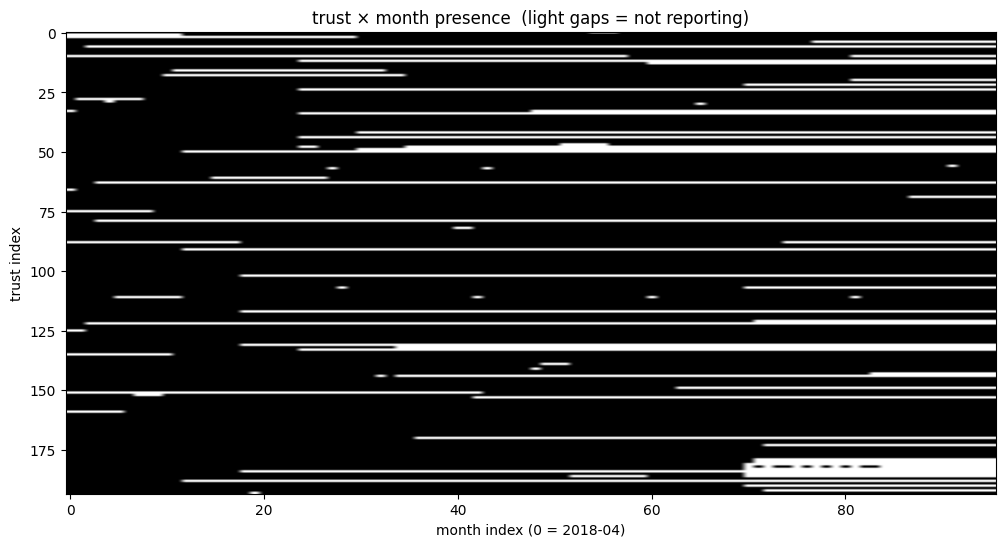

In [21]:
# Stage 3 · C2 — trust × month presence matrix. Dark = the trust reported that month,
#   light = a gap. Horizontal light streaks reveal entry/exit and reporting gaps.
pres = (canon.groupby(["branch", "date"]).size()             # rows per trust-month
             .unstack("date").notna())                       # True where the trust reported
plt.figure(figsize=(12, 6))
plt.imshow(pres.values, aspect="auto", cmap="Greys")          # dark = present, light = absent
plt.title("trust × month presence  (light gaps = not reporting)")
plt.xlabel("month index (0 = 2018-04)"); plt.ylabel("trust index")
plt.savefig(FIG / "03_presence_heatmap.png", dpi=150, bbox_inches="tight")

print("trusts present all 96 months:", int(pres.all(axis=1).sum()), "of", pres.shape[0])

In [22]:
# Stage 3 · C3 — which trusts entered after the window start or exited before its end.
#   These are mostly mergers/renames/reconfigurations, not data errors.
span = canon.groupby("branch").date.agg(["min", "max"])      # first & last month per trust
late = span[span["min"] > months[0]]                         # entered after 2018-04
early = span[span["max"] < months[-1]]                       # exited before 2026-03
print(len(late), "trusts enter late;", len(early), "exit early")
late.head(10)

11 trusts enter late; 45 exit early


,min,max
branch,,
R0B,2019-04-01,2026-03-01
R0D,2020-10-01,2026-03-01
R1L,2023-02-01,2024-12-01
RBZ,2018-05-01,2022-03-01
RH5,2018-05-01,2026-03-01
RJ7,2019-01-01,2026-03-01
RKL,2019-10-01,2024-05-01
RRE,2018-06-01,2026-03-01
RTE,2019-03-01,2026-03-01


In [23]:
# Stage 3 · C4 — separate the two kinds of "missing" at the trust×dept (series) level.
#   Gappy series (present some months, not all) = real reporting missingness.
#   Structural zeros = trust never offers that dept -> the pair is simply absent (no row).
sd = canon.groupby(["branch", "dept"]).date.nunique()        # months present per series
full = (sd == 96).sum()                                       # complete series (all 96 months)
print(f"series: {len(sd):,} | complete: {full:,} ({full/len(sd):.0%})")

gappy = sd[(sd > 0) & (sd < 96)]                             # present sometimes = has gaps
print("gappy series:", len(gappy), "| median months present:", int(gappy.median()))

offered = canon.groupby("branch").dept.nunique()             # how many depts each trust offers
print("depts offered per trust: min", int(offered.min()),
      "median", int(offered.median()), "max", int(offered.max()), "of 24")

series: 3,243 | complete: 1,412 (44%)
gappy series: 1831 | median months present: 60
depts offered per trust: min 1 median 20 max 24 of 24


In [24]:
# Stage 3 · C5 — NaN (unparseable/absent value) vs a literal 0 (a genuinely quiet month).
#   These are different things and must never be conflated: never fill NaN with 0.
print("NaN demand rows:", int(canon.demand.isna().sum()))
print("zero demand rows:", int((canon.demand == 0).sum()),
      f"({(canon.demand == 0).mean():.2%})")

NaN demand rows: 0
zero demand rows: 0 (0.00%)


### Stage 3 · findings & decision  →  copy to `docs/WORKLOG.md`

- **F-11** · Strict balanced panel: **125 of 194** trusts report in all 96 months (`reports/figures/03_presence_heatmap.png`).
- **F-12** · **11** trusts enter late, **45** exit early → exits dominate (NHS trust **mergers/consolidation**): a net loss of trusts across the window, not data gaps.
- **F-13** · **3,243** trust×dept series; **1,412 complete (44%)**, 1,831 gappy (median **60/96** months present). Trusts offer a median **20 of 24** depts → ~1,400 trust×dept pairs never appear = **structural zeros**.
- **F-14** · In the canonical table: **0 NaN** and **0 literal-zero** demand rows — every present row has demand ≥ 1. "Missingness" here is entirely *absent rows*; `NaN` appears only later when a series is reindexed to full monthly frequency (`asfreq("MS")`).

**D-02 — missingness rules:**
- trust **entry/exit** → handled by the panel choice (stage 4), *not* imputation
- **reporting gaps** inside an active series → keep as `NaN` after `asfreq("MS")`; the forecaster window skips them
- **structural zeros** (dept never offered) → absent rows, never imputed
- **literal `0`** demand → real data, kept (currently none exist)
- **`NaN`** demand cells → kept, counted, never silently filled with `0`

## Stage 4 · Characteristics

**Questions:** how **big** is demand, how **skewed**, how **spread** across trusts / depts / ICBs, and
what is the **balanced panel** at different strictness levels?

These fix two modelling facts: (1) demand is heavy-tailed and trust scale spans ~100× → **per-series
scaling** + size-aware FL weighting are mandatory; (2) the balanced panel defines the candidate
federated clients.

**Done when** `D-03` (candidate client panel) is logged.

count    227344.0
mean        632.9
std         778.4
min           1.0
25%         165.0
50%         428.0
75%         838.0
max       15807.0
Name: demand, dtype: float64
skew: 4.92


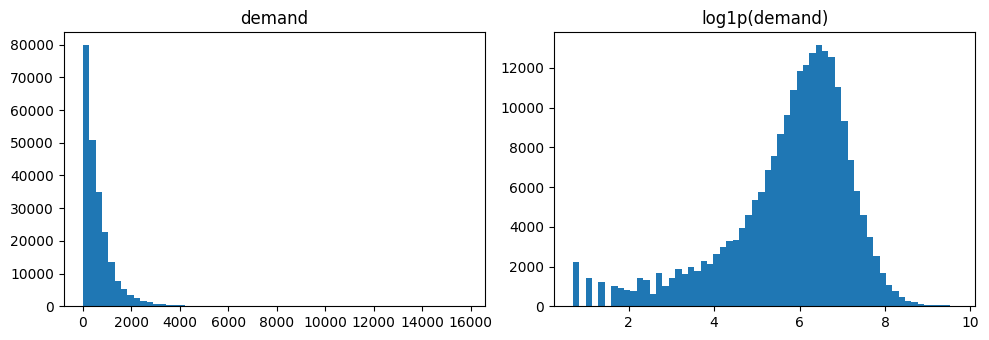

In [25]:
# Stage 4 · C1 — reload (keeps the stage runnable on its own) + C2 demand distribution.
#   Left: raw demand (expect heavy right skew). Right: log1p(demand) (expect roughly bell-ish,
#   maybe two humps = big vs small trusts). Implication: per-series scaling is mandatory.
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
FIG = ROOT / "reports" / "figures"

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(canon.demand.dropna(), bins=60); ax[0].set_title("demand")
ax[1].hist(np.log1p(canon.demand.dropna()), bins=60); ax[1].set_title("log1p(demand)")
fig.tight_layout(); fig.savefig(FIG / "04_demand_dist.png", dpi=150)

print(canon.demand.describe().round(1))
print("skew:", round(canon.demand.skew(), 2))

p90/p10 spread: 66.1 x
max/min: 2690.0 x


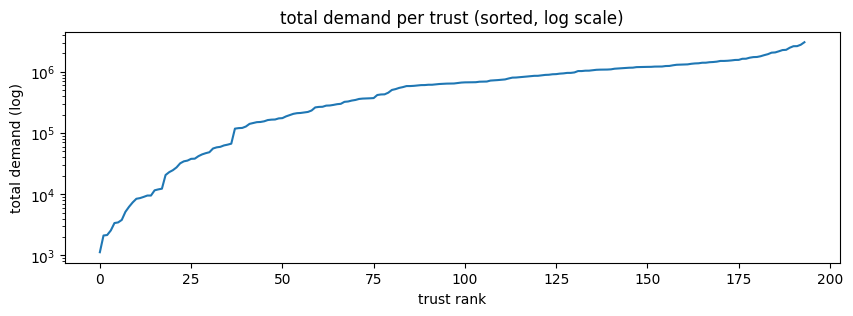

In [26]:
# Stage 4 · C3 — total demand per trust, sorted, on a log axis. The spread (p90/p10 and
#   max/min) is the federated-weighting fact: clients differ ~100x in size.
tt = canon.groupby("branch").demand.sum().sort_values()      # lifetime total per trust
plt.figure(figsize=(10, 3))
plt.semilogy(range(len(tt)), tt.values)                      # log y: straight-ish line = ~exponential spread
plt.title("total demand per trust (sorted, log scale)")
plt.xlabel("trust rank"); plt.ylabel("total demand (log)")
plt.savefig(FIG / "04_trust_volume.png", dpi=150, bbox_inches="tight")

print("p90/p10 spread:", round(tt.quantile(.9) / tt.quantile(.1), 1), "x")
print("max/min:", round(tt.max() / tt.min(), 0), "x")

In [27]:
# Stage 4 · C4 — which specialties dominate demand, and how widely each is offered.
#   Rare depts (offered by few trusts) weaken the "overlapping departments" requirement
#   for federation, so they are candidates to exclude from the client panel.
dt_ = canon.groupby("dept_name").demand.sum().sort_values(ascending=False)
print("top specialties by total demand:")
print(dt_.head(10))

cov = canon.groupby("dept").branch.nunique().sort_values(ascending=False)  # trusts offering each dept
print("\ntrusts offering each dept -- most common 3:")
print(cov.head(3))
print("...rarest 3:")
print(cov.tail(3))

top specialties by total demand:
dept_name
Other                             12541077
Other - Medical Services           9759797
Ophthalmology Service              8343640
Other - Surgical Services          7910330
Trauma and Orthopaedic Service     7677829
Gynaecology Service                6805855
Dermatology Service                5932809
Ear Nose and Throat Service        5857811
General Surgery Service            5208063
Gastroenterology Service           4912760
Name: demand, dtype: int64

trusts offering each dept -- most common 3:
dept
X01      189
C_110    157
C_320    150
Name: branch, dtype: int64
...rarest 3:
dept
C_170    95
X03      73
C_150    61
Name: branch, dtype: int64


In [28]:
# Stage 4 · C5 — the balanced panel at three strictness levels. 96 = present every month
#   (strict); 90 / 84 show what relaxing the rule buys. This is a supervisor decision, so
#   present all three rather than pre-deciding.
pm = canon.groupby("branch").date.nunique()                  # months present per trust
for k in (96, 90, 84):
    print(f"trusts with >= {k} of 96 months:", int((pm >= k).sum()))

trusts with >= 96 of 96 months: 125
trusts with >= 90 of 96 months: 139
trusts with >= 84 of 96 months: 146


In [29]:
# Stage 4 · C6 — trusts per ICB. The raw union of parent codes over the window is inflated
#   by the July-2022 CCG->ICB changeover, so the CORRECT hierarchy uses the latest month's
#   mapping (2026-03), where `Provider Parent` = the real ~42 ICBs.
icb_raw = canon.groupby("icb").branch.nunique()
print("raw union of parent codes over the window:", len(icb_raw), "distinct (inflated)")

latest = canon[canon.date == canon.date.max()]               # 2026-03 snapshot
icb_now = latest.groupby("icb").branch.nunique().sort_values(ascending=False)
print(len(icb_now), "ICBs in 2026-03 | trusts per ICB: min", int(icb_now.min()),
      "median", int(icb_now.median()), "max", int(icb_now.max()))
print("\nlargest ICBs by trust count:")
print(icb_now.head(10))

raw union of parent codes over the window: 56 distinct (inflated)
42 ICBs in 2026-03 | trusts per ICB: min 1 median 3 max 13

largest ICBs by trust count:
icb
QYG    13
QHM     9
QOP     7
QRV     6
QWO     6
QRL     5
QKS     5
QMJ     5
QE1     5
QF7     4
Name: branch, dtype: int64


### Stage 4 · findings & decision  →  copy to `docs/WORKLOG.md`

- **F-15** · Demand heavy right-skewed: mean **632.9** ≫ median **428**, skew **4.92**, range 1–15,807 → **per-series scaling mandatory**.
- **F-16** · Trust scale spread **p90/p10 = 66×**, max/min = 2690× → **size-aware FL weighting** (p90/p10 is the robust figure).
- **F-17** · Demand dominated by broad "Other" buckets (`X01`/`X02`/`X03`) + Ophthalmology, Trauma & Orthopaedic, Gynaecology, Dermatology, ENT. Every dept offered by ≥61 trusts; most common `X01` (189/194), rarest `C_150` (61).
- **F-18** · Balanced panel: **≥96 mo → 125** trusts · ≥90 mo → 139 · ≥84 mo → 146.
- **F-19** · Hierarchy (2026-03 mapping): **42 ICBs** (raw union 56, inflated by July-2022 CCG→ICB); trusts per ICB min 1 / median 3 / max 13.

**D-03 — candidate client panel.** Strict panel = **125 trusts** present in all 96 months; alternatives **139** (≥90 mo) and **146** (≥84 mo) recorded for the supervisor. Restrict to departments offered by a high share of panel trusts (exact threshold — e.g. ≥90% — is a supervisor choice; all 24 depts already have ≥61-trust coverage). **Per-series scaling + size-aware weighting mandatory** (F-15, F-16). Use the **2026-03 ICB mapping** for any hierarchical aggregation (F-19).

## Stage 5 · Transform decisions  (decide, do **not** transform)

**Questions:** what **scaling**, what **window length**, what **train/test split**, what **COVID
treatment**? This stage writes **no** transformed data — it only fixes the recipe, which is executed
later at model time (so scalers can be fitted on the train window only, avoiding leakage).

**Done when** `D-04` is logged.

In [30]:
# Stage 5 · C1 — a helper to pull one monthly series (explicit monthly index via asfreq,
#   so gap months become NaN, per D-02), then pick the busiest trust×dept to inspect.
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
FIG = ROOT / "reports" / "figures"

def series(branch, dept):
    s = (canon[(canon.branch == branch) & (canon.dept == dept)]
         .set_index("date").demand.sort_index().asfreq("MS"))  # MS = month-start frequency
    return s

big = canon.groupby(["branch", "dept"]).demand.sum().idxmax()  # busiest series key
s = series(*big)
print(big, "| months present:", int(s.notna().sum()), "of", len(s))

('RP6', 'C_130') | months present: 96 of 96


lag-1: 0.8 | lag-12: -0.01


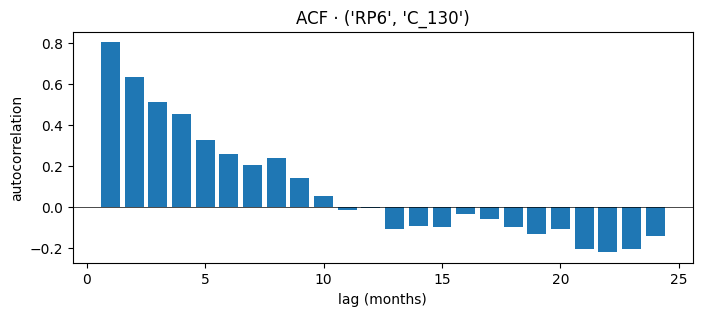

In [31]:
# Stage 5 · C2 — autocorrelation of the busiest series, computed by hand (no statsmodels).
#   Strong lag-1 = persistence; a lag-12 bump = an annual cycle. Together they set the
#   input window: it must cover at least one year, so window >= 12 (24 gives two cycles).
lags = range(1, 25)
acf = [s.autocorr(l) for l in lags]                          # pandas autocorr per lag
plt.figure(figsize=(8, 3)); plt.bar(list(lags), acf)
plt.axhline(0, color="k", lw=.5); plt.title(f"ACF · {big}")
plt.xlabel("lag (months)"); plt.ylabel("autocorrelation")
plt.savefig(FIG / "05_acf_busiest.png", dpi=150, bbox_inches="tight")

print("lag-1:", round(acf[0], 2), "| lag-12:", round(acf[11], 2))

In [32]:
# Stage 5 · C3 — the train/test split. Rule: time-based, per series, last 12 months held
#   out; scalers fitted on TRAIN only (checked here, executed at model time).
months = pd.Index(sorted(canon.date.unique()))
split = months[-12]                                          # first month of the 12-month holdout
print("train:", months[0].date(), "->", (split - pd.offsets.MonthBegin(1)).date(),
      "| test:", split.date(), "->", months[-1].date())

train: 2018-04-01 -> 2025-03-01 | test: 2025-04-01 -> 2026-03-01


### Stage 5 · findings & decision  →  copy to `docs/WORKLOG.md`

- **F-20** · Busiest series (`RP6·C_130`, Moorfields Ophthalmology): **lag-1 = 0.80** (strong persistence), **lag-12 = −0.01**. The annual cycle is *masked by the COVID regime shift* in raw autocorrelation, not absent — genuine seasonality is quantified panel-wide in stage 6.

**D-04 — transforms (executed at model time, not now):**
- **per-series standardisation**, statistics fitted on the **TRAIN window only**
- input **window = 12 months** (baseline) to 24 (two cycles) + **calendar features** (month sin/cos or one-hot)
- **split:** train `2018-04 → 2025-03`, test `2025-04 → 2026-03` (last 12 months held out)
- **COVID:** regime flag for `2020-03 → 2021-03` (confirm exact span in stage 7), no deletion
- **no leakage:** nothing fitted on, or peeking at, the test window

## Stage 6 · Visualise relationships

**Questions:** what do the series actually look like; how strong and how **shared** are seasonality,
trend, and the COVID shock? Shared shocks across trusts are the evidence that a federated model has
common structure to learn (while heterogeneous scale/casemix is what personalisation handles).

**Done when** quantified findings `F-21..24` are logged. The sample is **pre-registered** (busiest /
median / sparsest by total demand) *before* plotting — the cherry-picking defence.

In [33]:
# Stage 6 · C1 — fix the sample BEFORE plotting: busiest / median / sparsest by total demand.
#   Choosing the rule first (not after seeing the charts) is the anti-cherry-pick guard.
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
FIG = ROOT / "reports" / "figures"

tot = canon.groupby(["branch", "dept"]).demand.sum().sort_values()
keys = {"busiest": tot.index[-1],
        "median":  tot.index[len(tot) // 2],
        "sparsest": tot.index[0]}
print(keys)

{'busiest': ('RP6', 'C_130'), 'median': ('RXH', 'C_330'), 'sparsest': ('R0B', 'C_170')}


national trough: 2020-04-01 (474,295) | baseline 2018-04: 1,544,011 | latest 2026-03: 1,783,457


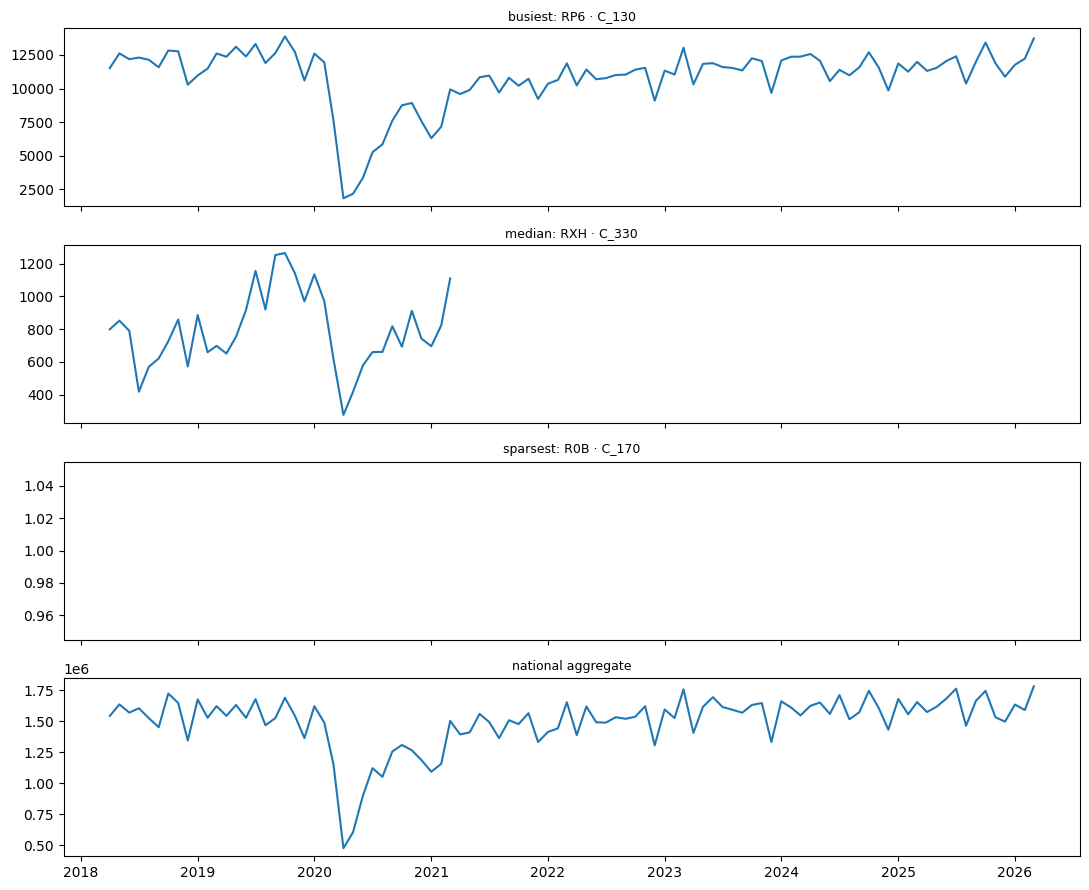

In [34]:
# Stage 6 · C2 — the three pre-registered series + the national aggregate. Look for the
#   2020-04 collapse in all of them, the recovery ramp, growth above baseline after ~2023,
#   and whether the sparsest series is usable at all.
fig, ax = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for a, (name, (b, d)) in zip(ax, keys.items()):
    s = (canon[(canon.branch == b) & (canon.dept == d)]
         .set_index("date").demand.sort_index())
    a.plot(s.index, s.values); a.set_title(f"{name}: {b} · {d}", fontsize=9)
nat = canon.groupby("date").demand.sum()
ax[3].plot(nat.index, nat.values); ax[3].set_title("national aggregate", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "06_sample_series.png", dpi=150)

print("national trough:", nat.idxmin().date(), f"({nat.min():,.0f})",
      "| baseline 2018-04:", f"{nat.loc['2018-04-01']:,.0f}",
      "| latest 2026-03:", f"{nat.iloc[-1]:,.0f}")

lowest 3 months: [12, 4, 8] | highest 3 months: [2, 1, 3]


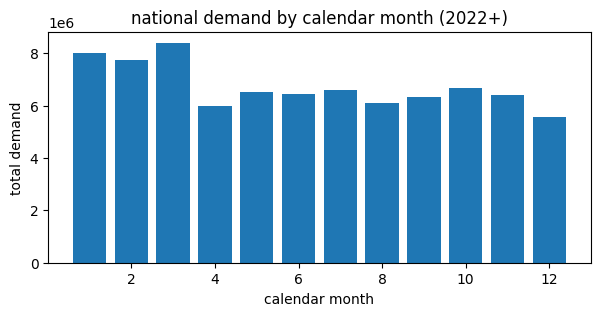

In [35]:
# Stage 6 · C3 — national demand by calendar month, on a clean post-COVID window (2022+),
#   to expose the seasonal shape without the shock. Expect holiday-month dips.
post = canon[canon.date >= "2022-01-01"]                     # clean window
moy = post.groupby(post.date.dt.month).demand.sum()          # month-of-year totals
plt.figure(figsize=(7, 3)); plt.bar(moy.index, moy.values)
plt.title("national demand by calendar month (2022+)")
plt.xlabel("calendar month"); plt.ylabel("total demand")
plt.savefig(FIG / "06_month_of_year.png", dpi=150, bbox_inches="tight")

print("lowest 3 months:", list(moy.sort_values().head(3).index),
      "| highest 3 months:", list(moy.sort_values().tail(3).index))

In [36]:
# Stage 6 · C4 — how many series actually carry an annual cycle (lag-12 autocorr > 0.3),
#   counted across every series with enough history. This is the panel-wide seasonality
#   number for the report (not a single cherry-picked series).
hit = n = 0
for (b, d), g in canon.groupby(["branch", "dept"]):
    s = g.set_index("date").demand.sort_index().asfreq("MS")
    if s.notna().sum() >= 48:                                # need >= 4 years of history
        n += 1
        if (s.autocorr(12) or 0) > 0.3:                      # yearly cycle present?
            hit += 1
print(f"lag-12 autocorr > 0.3 in {hit}/{n} series ({hit/n:.0%})")

lag-12 autocorr > 0.3 in 940/2464 series (38%)


dept: C_130 (biggest by code) | median pairwise corr: 0.63


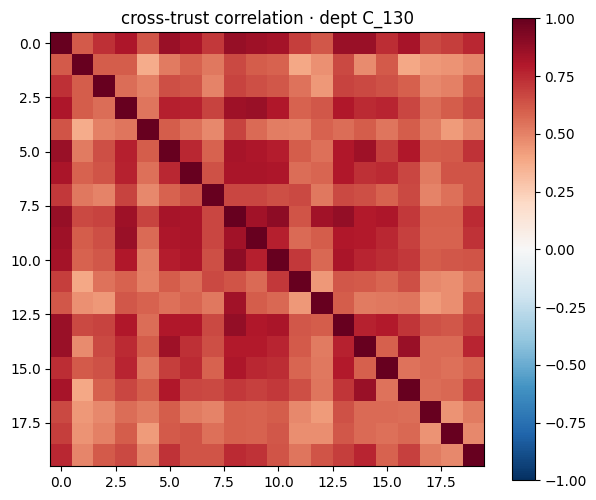

In [37]:
# Stage 6 · C5 — do trusts move together? Correlate month-over-month changes across the 20
#   biggest trusts in the biggest department (by CODE — codes are stable, names drift).
#   Broadly positive = shared national shocks (structure a federated model can learn).
d0 = canon.groupby("dept").demand.sum().idxmax()             # biggest department by code
w = canon[canon.dept == d0].pivot_table("demand", "date", "branch")  # date × trust matrix
top = w.sum().nlargest(20).index                             # 20 biggest trusts in it
corr = w[top].pct_change(fill_method=None).corr()            # co-movement (don't forward-fill gaps)
plt.figure(figsize=(7, 6)); plt.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar(); plt.title(f"cross-trust correlation · dept {d0}")
plt.savefig(FIG / "06_crosstrust_corr.png", dpi=150, bbox_inches="tight")

med = np.nanmedian(corr.values[np.triu_indices(len(top), 1)])  # median off-diagonal pair
print("dept:", d0, "(biggest by code) | median pairwise corr:", round(med, 2))

### Stage 6 · findings  →  copy to `docs/WORKLOG.md`

- **F-21** · Sample (busiest `RP6·C_130`, median `RXH·C_330`, sparsest `R0B·C_170`) + national all show the **2020-04 collapse** (474,295 = 31% of baseline), the recovery ramp, and growth to **≈116%** of the 2018 baseline by 2026-03. (`06_sample_series.png`)
- **F-22** · Seasonality (2022+ window): lowest calendar months **Dec / Apr / Aug**, highest **Feb / Jan / Mar** (winter + March fiscal year-end). (`06_month_of_year.png`)
- **F-23** · Annual cycle is panel-wide: lag-12 autocorr > 0.3 in **940/2464 series (38%)** — real despite COVID masking the single busiest series (cf. F-20).
- **F-24** · Cross-trust co-movement (biggest dept `C_130`, 20 largest trusts): median pairwise corr of monthly changes = **0.63** → strong **shared national shocks** = structure a federated model can learn. (`06_crosstrust_corr.png`)

> **Data note (reinforces D-01):** treatment-function **codes are stable but names drift across eras** — `C_130` carries ≥2 name spellings, so grouping by *code* gives 13.0M vs 8.3M for the latest name alone. Keying the canonical `dept` on the **code** (not the name) was correct. Also `X01` "Other" spans only 36 months — the X-code taxonomy shifted mid-window.

## Stage 7 · Outliers

**Questions:** which points are anomalous, what **species** is each (COVID / reporting spike /
zero-blip / genuine surge), and what **action** per species? Nothing is deleted — every flag goes
into a **register** (the audit trail) and gets a per-species rule.

Detection is **robust** (rolling median + MAD, |z| > 4) so the flags aren't themselves distorted by
the COVID shock they need to find.

**Done when** the outlier register CSV exists and `D-05` is logged.

In [38]:
# Stage 7 · C1 — flag extreme points per series with a robust z-score (rolling median +
#   MAD, |z| > 4). Robust stats resist the very shocks we are trying to detect.
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
OUT = ROOT / "reports" / "tables"

def flags(g):                                                # one series in, extreme points out
    s = g.set_index("date").demand.sort_index()
    med = s.rolling(13, center=True, min_periods=7).median()             # local level
    mad = (s - med).abs().rolling(13, center=True, min_periods=7).median()  # robust spread
    z = (s - med) / (1.4826 * mad.replace(0, np.nan))        # robust z-score (1.4826 ~ MAD->sigma)
    return z[abs(z) > 4]                                     # only the extremes

out = []
for (b, d), g in canon.groupby(["branch", "dept"]):
    if g.date.nunique() >= 36:                               # enough history to judge
        for t, z in flags(g).items():
            out.append({"branch": b, "dept": d, "date": t, "z": round(float(z), 1)})
reg = pd.DataFrame(out)
print(len(reg), "flags total")
print("top flagged months:")
print(reg.date.dt.to_period("M").value_counts().head(6))

4183 flags total
top flagged months:
date
2020-04    354
2020-05    218
2023-12    209
2018-12    133
2021-03    115
2022-03    110
Freq: M, Name: count, dtype: int64


In [39]:
# Stage 7 · C2 — first-pass classification by rule, then persist the register (audit trail).
#   COVID window is treated as its own class; other positives = spikes, negatives = drops.
#   (A later manual pass can eyeball non-COVID flags and correct the CSV by hand.)
def classify(row):
    m = row.date.to_period("M")
    if pd.Period("2020-03") <= m <= pd.Period("2021-03"):    # the COVID regime window
        return "covid"
    if row.z > 0:
        return "spike"                                       # positive jump
    return "drop"                                            # negative dip / zero-blip

reg["cls"] = reg.apply(classify, axis=1)
print(reg.cls.value_counts())
reg.to_csv(OUT / "07_outlier_register.csv", index=False)
print("saved register:", OUT / "07_outlier_register.csv", "|", len(reg), "rows")

cls
spike    1961
drop     1329
covid     893
Name: count, dtype: int64
saved register: /home/garima/fedOPD/reports/tables/07_outlier_register.csv | 4183 rows


### Stage 7 · findings & decision  →  copy to `docs/WORKLOG.md`

- **F-25** · **4,183** robust flags (|z| > 4 on ≥36-month series). Dominant clusters: **COVID** (2020-04: 354, 2020-05: 218) + **December** dips (2023-12: 209 — Dec-2023 strikes; 2018-12: 133) + **March** fiscal spikes (2021-03, 2022-03).
- **F-26** · Classified: **spike 1,961 · drop 1,329 · covid 893**. Register saved → `reports/tables/07_outlier_register.csv`. COVID span `2020-03 → 2021-03` confirmed by the clustering (resolves D-04's open span).

**D-05 — outlier actions by class:**
- **covid** (`2020-03 → 2021-03`) → **regime-flag feature; KEEP** values
- **reporting spike / drop / zero-blip** → flag; **exclude from scaler fitting; KEEP** in data
- **genuine surge** → keep untouched (it is signal)
- **nothing deleted**; the register CSV is the audit trail

## Stage 8 · Communicate

**Questions:** none new — **assemble**. A key-numbers table (every figure traceable to the stage that
produced it) and a prose EDA summary, plus the open questions for the supervisor.

**Done when** the summary exists and the supervisor questions are written. **The EDA gate then opens:**
`D-01..D-05` exist → build the loader interface, transforms, forecaster, and the federated loop.

In [40]:
# Stage 8 · C1 — the headline numbers in one place; each should match its stage of origin.
canon = pd.read_parquet(ROOT / "reports" / "tables" / "rtt_canonical.parquet")
pm = canon.groupby("branch").date.nunique()
tt = canon.groupby("branch").demand.sum()
summary = {
    "months":             canon.date.nunique(),
    "trusts_union":       canon.branch.nunique(),
    "depts":              canon.dept.nunique(),
    "series":             canon.groupby(["branch", "dept"]).ngroups,
    "balanced_panel_96":  int((pm == 96).sum()),
    "balanced_panel_90":  int((pm >= 90).sum()),
    "scale_p90_p10":      round(tt.quantile(.9) / tt.quantile(.1), 1),
    "icbs_latest":        canon[canon.date == canon.date.max()].icb.nunique(),
}
for k, v in summary.items():
    print(f"{k:>18}: {v}")

            months: 96
      trusts_union: 194
             depts: 24
            series: 3243
 balanced_panel_96: 125
 balanced_panel_90: 139
     scale_p90_p10: 66.1
       icbs_latest: 42


### EDA summary · fedOPD   →  copy to `docs/PROJECT.md` / `docs/WORKLOG.md`

1. **Data.** 96 months × **194 trusts** (union) × **24 depts** = **3,243 series**; schema uniform in the 9 canonical columns; national totals externally validated **4/4** (F-06, F-10).
2. **Quality.** **125 trusts** complete all 96 months (139 at ≥90 mo); trust entry/exit dominated by mergers (F-12); gaps, structural zeros and literal-0 separated (D-02); **0 NaN / 0 zero** in the built table (F-14).
3. **Shape.** Demand heavily skewed (skew **4.92**); trust scale spread **~66×** (p90/p10) → **per-series scaling + size-aware FL weighting** (F-15, F-16).
4. **Dynamics.** lag-12 seasonality in **38%** of series (F-23); low months Dec/Apr/Aug, high Feb/Jan/Mar (F-22); **COVID collapse to 31%** of baseline in 2020-04, flagged as a regime and kept (D-05).
5. **Federation evidence.** Shared national shocks (median cross-trust corr **0.63**, F-24) **+** heterogeneous scale/casemix → shared structure *and* per-client differences: exactly the setting where **personalised FL** should win.
6. **Recommendation.** Client panel = **125 trusts** (96-month, D-03); departments offered by a high share of panel trusts; input window **12–24 months**; last 12 months (`2025-04 → 2026-03`) held out (D-04); **42-ICB** latest-month hierarchy for aggregation (F-19).

**Open questions for supervisor:** panel strictness (96 / 90 / 84 months) · COVID span (`2020-03 → 2021-03`) · small-trust inclusion · department-coverage threshold.

**Gate open:** `D-01..D-05` logged → build the forecaster interface (`get_params`/`set_params`), the transforms, and the Flower federated loop.